# Nutrition5k: resultados MobileNet

No entrena nada: lee los runs de `outputs/mobilenet/` (los escribe `experiments.ipynb` de esta carpeta) con las
funciones de `src/nutrition5k/results.py`. Elegir siempre por **validación** (`val_mean_pmae`); test se informa pero no
decide. `test_clean_mean_pmae` es el test oficial sin los platos de `data/nutrition5k/excluded_dishes.csv`.

Los runs anteriores a `preprocess` (validación plato a plato y platos con etiquetas erróneas en train) están archivados
en `outputs/previous_runs_to_data_preprocess/`; se ven con `PREVIOUS = True`. Sus valores no son comparables con los
nuevos.

In [1]:
import os
from pathlib import Path

if Path("/workspace").is_dir():  # RunPod
    # The clone made by experiments.ipynb: outputs/ links to the volume and data/ holds the frames.
    os.chdir("/root/thesis-multimodal-health-ai")
elif Path.cwd().parent.name == "notebooks":
    os.chdir("../..")

import pandas as pd

from nutrition5k.results import (
    baseline_row, compare, cost, gallery, load_runs, seed_files, seed_groups, seed_spread, seed_table,
    seed_targets, select, steps, target_curves, target_table, test_metrics,
)

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)

FAMILY = "mobilenet"
SPLIT = "pilot"         # "full" o "pilot"
MODE = "complete"      # modo de frames a comparar
PREVIOUS = False      # True: runs anteriores a `preprocess`
OLD_ROOT = Path("outputs/previous_runs_to_data_preprocess")

all_runs = load_runs([FAMILY], SPLIT, MODE, root=OLD_ROOT if PREVIOUS else Path("outputs"))
assert len(all_runs), f"no runs of {FAMILY} in {SPLIT}; train them with experiments.ipynb"
runs = select(all_runs, recipe="fbn" if PREVIOUS else "fbn+clean")  # the recipe of the current runs; all_runs keeps every recipe
BASELINE = baseline_row(SPLIT)
print(f"{len(all_runs)} runs ({len(runs)} with the current recipe); baseline mean PMAE: "
      f"val {BASELINE['val_mean_pmae'].iloc[0]}, test {BASELINE['test_mean_pmae'].iloc[0]}")
runs

27 runs (27 with the current recipe); baseline mean PMAE: val 68.78185594884593, test 55.11396595533928


,run,path,family,backbone,recipe,unfreeze,heads,hidden,image_size,backbone_lr,seed,params_M,trainable_M,epochs_done,best_epoch,sec_per_epoch,gpu,gpu_memory_gb,status,val_mean_pmae,test_mean_pmae,test_clean_mean_pmae,val_total_mass_pmae,val_total_mass_mae,val_total_mass_rmse,val_total_mass_rsquared,val_total_calories_pmae,val_total_calories_mae,val_total_calories_rmse,val_total_calories_rsquared,val_total_fat_pmae,val_total_fat_mae,val_total_fat_rmse,val_total_fat_rsquared,val_total_carb_pmae,val_total_carb_mae,val_total_carb_rmse,val_total_carb_rsquared,val_total_protein_pmae,val_total_protein_mae,val_total_protein_rmse,val_total_protein_rsquared,test_total_mass_pmae,test_total_mass_mae,test_total_mass_rmse,test_total_mass_rsquared,test_total_calories_pmae,test_total_calories_mae,test_total_calories_rmse,test_total_calories_rsquared,test_total_fat_pmae,test_total_fat_mae,test_total_fat_rmse,test_total_fat_rsquared,test_total_carb_pmae,test_total_carb_mae,test_total_carb_rmse,test_total_carb_rsquared,test_total_protein_pmae,test_total_protein_mae,test_total_protein_rmse,test_total_protein_rsquared
25,v4m-r256-ft_2-single-h0-256-complete-pilot-fbn...,outputs/mobilenet/pilot/v4m-r256/v4m-r256-ft_2...,mobilenet,v4m-r256,fbn+clean,2,single,0,256,0.0001,2,8.763733,7.138853,3,2,9.872804,None,NaN,done,49.785732,63.956204,63.956204,42.103437,139.923757,201.345591,0.046211,27.233050,70.341306,79.580052,0.695381,68.125125,10.433409,12.408370,0.531494,44.416069,7.114749,7.135668,-0.225388,67.050977,20.521904,25.226009,-0.531686,40.571374,46.707794,60.051761,-0.900899,54.051110,147.671839,162.941706,-0.100888,75.062903,14.170423,17.511730,-0.295558,67.817836,9.187315,10.656375,-1.414503,82.277799,11.817247,14.596219,-1.441634
23,v4m-r256-ft_2-single-h0-256-complete-pilot-fbn...,outputs/mobilenet/pilot/v4m-r256/v4m-r256-ft_2...,mobilenet,v4m-r256,fbn+clean,2,single,0,256,0.0001,0,8.763733,7.138853,3,2,9.840450,None,NaN,done,51.599373,57.176817,57.176817,44.811408,148.923246,215.325071,-0.090830,36.482524,94.232132,102.726360,0.492410,72.847261,11.156607,14.089230,0.395968,36.035488,5.772313,7.101044,-0.213525,67.820183,20.757330,23.644649,-0.345669,50.554475,58.200839,62.762673,-1.076397,54.969304,150.180418,191.271790,-0.516982,80.846910,15.262331,20.248237,-0.732101,45.710590,6.192436,7.214119,-0.106561,53.802807,7.727492,8.989488,0.073875
16,v4m-ft_2-single-h0-224-complete-pilot-fbn-clea...,outputs/mobilenet/pilot/v4m/v4m-ft_2-single-h0...,mobilenet,v4m,fbn+clean,2,single,0,224,0.0001,0,8.763733,7.138853,3,2,8.396772,None,NaN,done,55.198605,56.472905,56.472905,48.214433,160.232633,231.024797,-0.255698,41.323059,106.734940,114.578610,0.368525,76.365650,11.695451,15.956965,0.225206,32.502975,5.206461,5.754473,0.203079,77.586909,23.746576,28.090980,-0.899356,36.306435,41.797784,50.883985,-0.364803,56.232192,153.630725,191.953784,-0.527819,84.533431,15.958275,20.742641,-0.817720,37.913869,5.136210,7.821333,-0.300680,67.378598,9.677331,12.122332,-0.684117
17,v4m-ft_2-single-h0-224-complete-pilot-fbn-clea...,outputs/mobilenet/pilot/v4m/v4m-ft_2-single-h0...,mobilenet,v4m,fbn+clean,2,single,0,224,0.0001,1,8.763733,7.138853,3,2,8.549787,None,NaN,done,56.936974,52.277238,52.277238,59.986053,199.353650,272.255325,-0.743896,33.829616,87.379835,101.189660,0.507483,87.076765,13.335865,15.925252,0.228283,39.271234,6.290628,7.654669,-0.410124,64.521202,19.747631,21.656036,-0.128835,28.565465,32.885991,42.861731,0.031617,54.000146,147.532601,182.882241,-0.386825,79.138320,14.939782,18.170979,-0.394940,48.507552,6.571342,8.031567,-0.371543,51.174709,7.350028,8.714128,0.129743
14,v4m-ft_2-grouped-h512-224-complete-pilot-fbn-c...,outputs/mobilenet/pilot/v4m/v4m-ft_2-grouped-h...,mobilenet,v4m,fbn+clean,2,grouped,512,224,0.0001,0,9.485653,7.860773,3,2,8.499628,None,NaN,done,57.640275,57.980899,57.980899,56.452724,187.611219,273.684490,-0.762253,42.132902,108.826714,129.547856,0.192747,73.746407,11.294312,13.509867,0.444623,43.598451,6.983780,8.502089,-0.739

## Etapa 1 (L1): arquitecturas (fine-tuning completo, cabeza `single`, 512, 224 px, lr del backbone 1e-4, semilla 0)

Resumen (`best_epoch` es la época con el menor `val_mean_pmae`, la que se guarda en `best.pt` y se evalúa), tabla de
validación con PMAE, MAE, RMSE y R² por objetivo (en verde el mejor de cada columna; MAE y RMSE en g o kcal), PMAE por
objetivo en barras y curvas de validación (el círculo grande marca la mejor época). La fila `baseline` es la línea
base de la media (predice la media de train para todos los platos) sobre la misma validación.

,run,status,epochs_done,best_epoch,val_mean_pmae,test_mean_pmae,test_clean_mean_pmae,params_M,trainable_M,sec_per_epoch,model
22,v4m-ft_all-single-h512-224-complete-pilot-fbn-...,done,3.0,2.0,60.998324,59.158896,59.158896,9.222997,9.222997,10.878709,v4m ft all
0,v2-ft_all-single-h512-224-complete-pilot-fbn-c...,done,3.0,2.0,61.453845,53.739471,53.739471,3.012357,3.012357,10.545013,v2 ft all
11,v3-ft_all-single-h512-224-complete-pilot-fbn-c...,done,3.0,2.0,63.043024,56.497537,56.497537,4.990517,4.990517,9.508131,v3 ft all
26,v4s-ft_all-single-h512-224-complete-pilot-fbn-...,done,3.0,2.0,67.212363,62.810647,62.810647,3.281509,3.281509,6.445609,v4s ft all
0,average baseline,done,NaN,NaN,68.781856,55.113966,55.113966,0.000000,0.000000,NaN,baseline


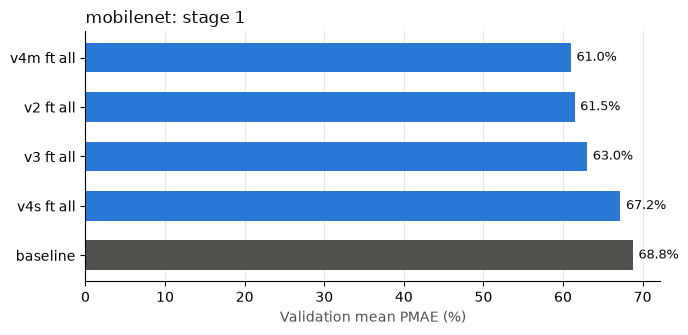

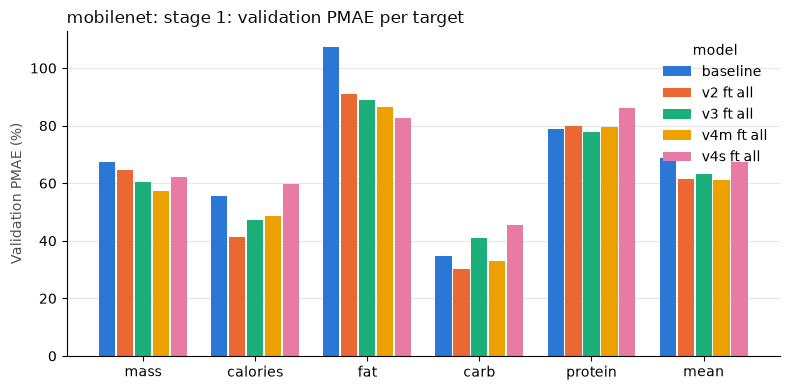

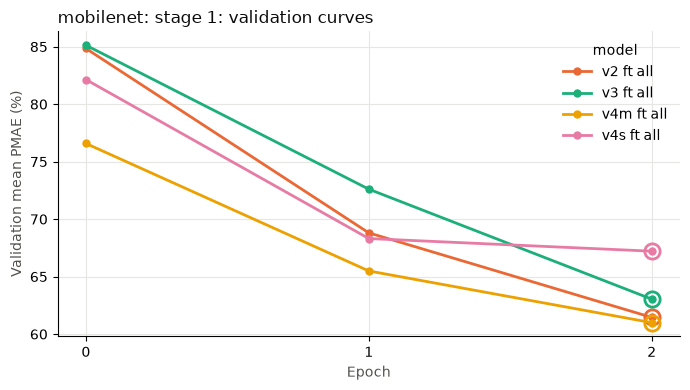

In [2]:
STAGE1 = dict(heads="single", hidden="512", image_size=224, backbone_lr=1e-4, seed=0)
stage1 = select(runs, unfreeze="all", **STAGE1)
stage1 = stage1.assign(model=stage1["backbone"] + " ft " + stage1["unfreeze"])
compare(stage1, "model", f"{FAMILY}: stage 1", baseline=BASELINE)

### Etapa 1 con las otras recetas

Solo con `PREVIOUS = True`: `bn` (BN actualizada, antes de 2026-10-20) y `bn+cosine` (solo `v4m`). No son
comparables con `fbn` época a época.

In [3]:
for other in sorted(set(all_runs["recipe"]) - set(runs["recipe"])):
    chosen = select(all_runs, recipe=other, unfreeze="all", **STAGE1)
    compare(chosen.assign(model=chosen["backbone"]), "model", f"Stage 1 ({other})", baseline=BASELINE)

### Etapa 1: coste computacional

- `params_M`: parámetros en millones (backbone, tronco y cabezas). `size_MB`: tamaño de `best.pt` (float32).
- `MMACs`: millones de multiplicaciones-acumulaciones por imagen a la resolución del run; no depende del hardware.
- `cpu_ms`: latencia mediana de una imagen (batch 1) en la CPU de esta máquina, con pesos aleatorios. Solo compara
  backbones entre sí en la misma máquina; la latencia que cuenta es la del dispositivo.
- `gpu_memory_gb` y `sec_per_epoch`: pico de memoria de GPU y segundos por época **del entrenamiento**.

/home/abello/Desktop/harness-thesis-multimodal-health-ai/code/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


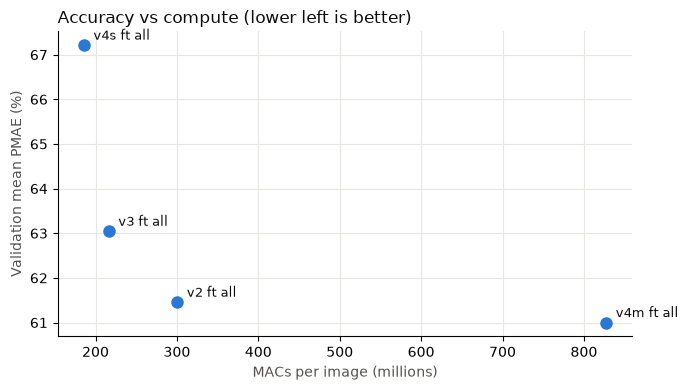

,family,val_mean_pmae,params_M,size_MB,MMACs,cpu_ms,gpu_memory_gb,sec_per_epoch,gpu
model,,,,,,,,,
v4m ft all,mobilenet,60.998324,9.222997,37.312137,827.157696,16.985850,NaN,10.878709,None
v2 ft all,mobilenet,61.453845,3.012357,12.280503,300.281984,18.253534,NaN,10.545013,None
v3 ft all,mobilenet,63.043024,4.990517,20.156993,216.097472,10.061189,NaN,9.508131,None
v4s ft all,mobilenet,67.212363,3.281509,13.315819,185.513280,7.549135,NaN,6.445609,None


In [4]:
cost(stage1, "model")

## Etapa 2 (L2): ablaciones

Cada finalista sigue su propio camino greedy (mismos `BACKBONES` y `BEST_*` que en `experiments.ipynb`).
Cada paso compara el valor del factor dentro del backbone; menos de ~1 punto es empate.

v3 - Step 1: fine-tuning depth


,run,status,epochs_done,best_epoch,val_mean_pmae,test_mean_pmae,test_clean_mean_pmae,params_M,trainable_M,sec_per_epoch,unfreeze
11,v3-ft_all-single-h512-224-complete-pilot-fbn-c...,done,3,2,63.043024,56.497537,56.497537,4.990517,4.990517,9.508131,all
7,v3-ft_2-single-h512-224-complete-pilot-fbn-cle...,done,3,2,63.534907,57.639752,57.639752,4.990517,4.198029,8.035594,2
1,v3-ft_0-single-h512-224-complete-pilot-fbn-cle...,done,3,2,64.435921,58.265877,58.265877,4.990517,0.788485,7.751220,0
2,v3-ft_1-single-h512-224-complete-pilot-fbn-cle...,done,3,2,64.465700,58.046900,58.046900,4.990517,2.174085,9.414750,1


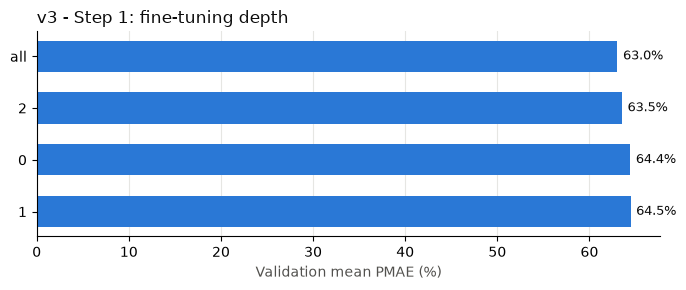

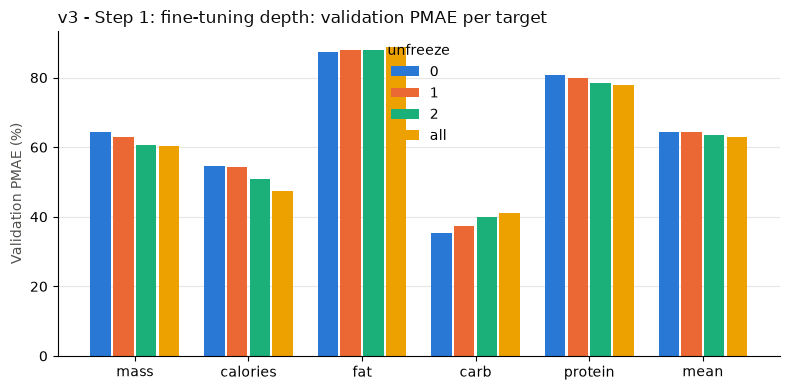

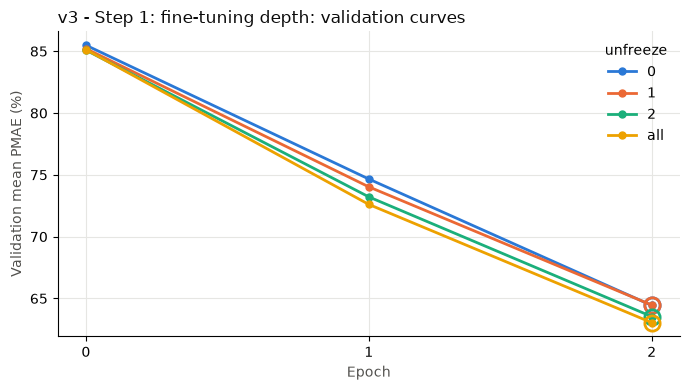

v3 - Step 2: head grouping


,run,status,epochs_done,best_epoch,val_mean_pmae,test_mean_pmae,test_clean_mean_pmae,params_M,trainable_M,sec_per_epoch,heads
4,v3-ft_2-per-target-h512-224-complete-pilot-fbn...,done,3,2,59.796366,57.102631,57.102631,5.515829,4.723341,7.778475,per-target
3,v3-ft_2-grouped-h512-224-complete-pilot-fbn-cl...,done,3,2,59.933438,60.986714,60.986714,5.253173,4.460685,7.610976,grouped
7,v3-ft_2-single-h512-224-complete-pilot-fbn-cle...,done,3,2,63.534907,57.639752,57.639752,4.990517,4.198029,8.035594,single


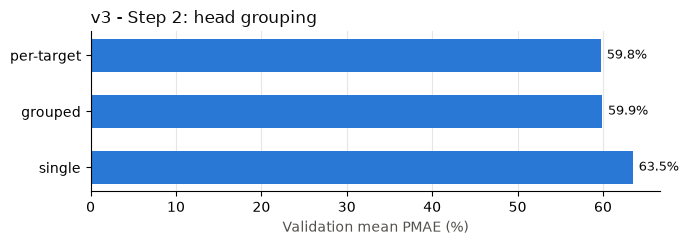

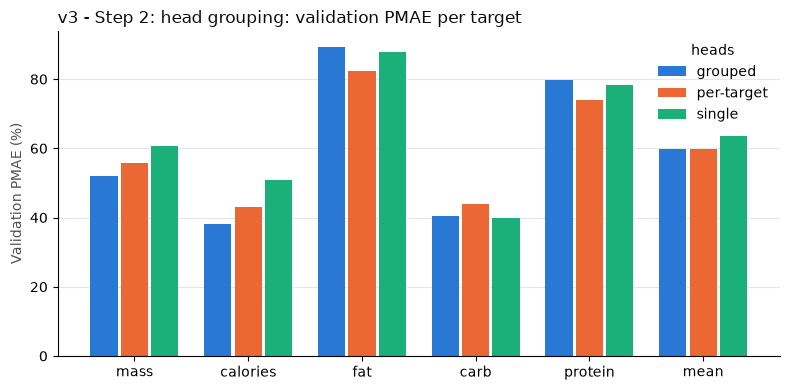

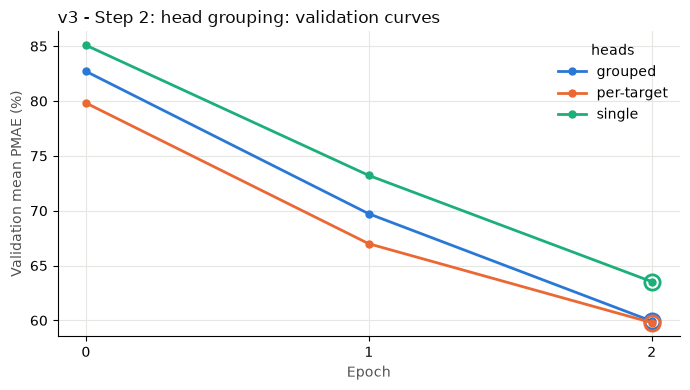

v3 - Step 3: trunk size


,run,status,epochs_done,best_epoch,val_mean_pmae,test_mean_pmae,test_clean_mean_pmae,params_M,trainable_M,sec_per_epoch,hidden
7,v3-ft_2-single-h512-224-complete-pilot-fbn-cle...,done,3,2,63.534907,57.639752,57.639752,4.990517,4.198029,8.035594,512
5,v3-ft_2-single-h0-224-complete-pilot-fbn-clean-s0,done,3,2,65.039042,59.250130,59.250130,4.531253,3.738765,7.813843,0
6,v3-ft_2-single-h1024x1024-224-complete-pilot-f...,done,3,2,65.045546,68.310840,68.310840,6.827061,6.034573,7.661349,1024x1024


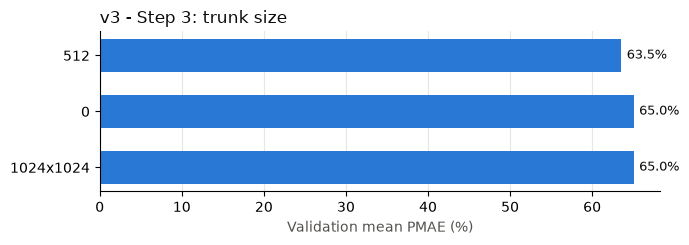

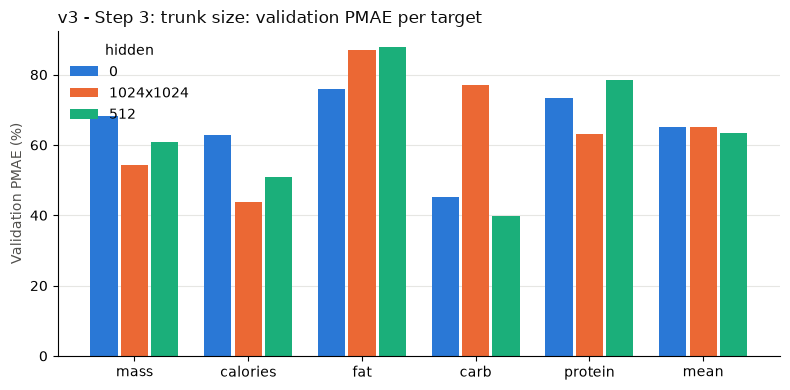

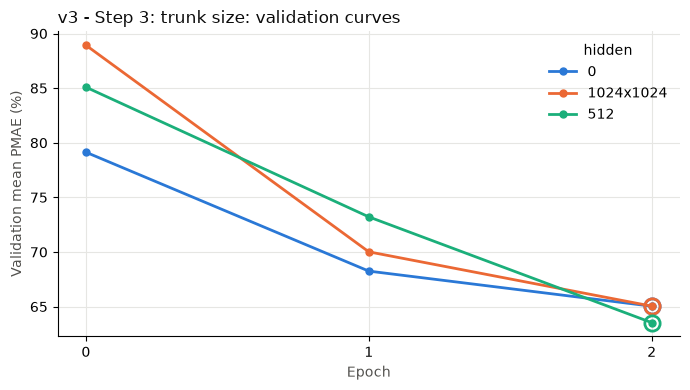

v3 - Step 4: image size


,run,status,epochs_done,best_epoch,val_mean_pmae,test_mean_pmae,test_clean_mean_pmae,params_M,trainable_M,sec_per_epoch,image_size
7,v3-ft_2-single-h512-224-complete-pilot-fbn-cle...,done,3,2,63.534907,57.639752,57.639752,4.990517,4.198029,8.035594,224
10,v3-ft_2-single-h512-256-complete-pilot-fbn-cle...,done,3,2,63.618692,57.709592,57.709592,4.990517,4.198029,9.167515,256


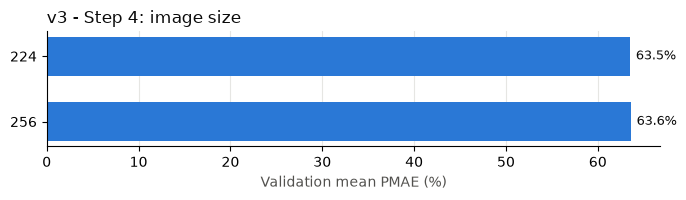

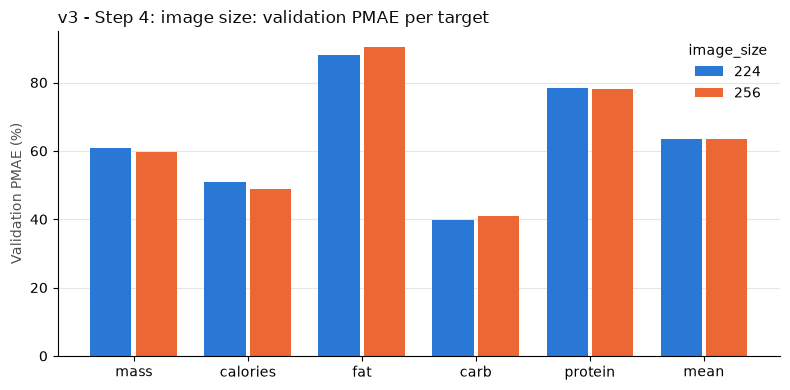

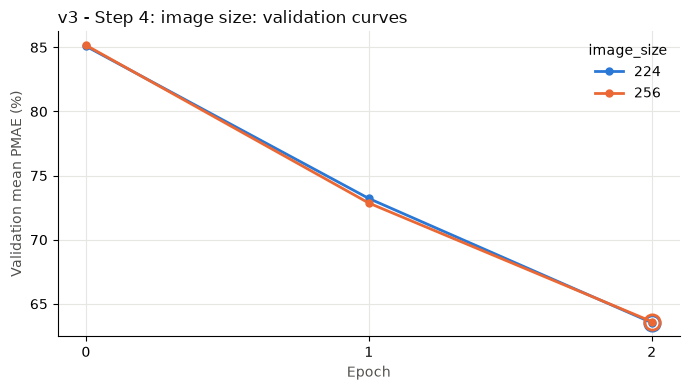

v4m - Step 1: fine-tuning depth


,run,status,epochs_done,best_epoch,val_mean_pmae,test_mean_pmae,test_clean_mean_pmae,params_M,trainable_M,sec_per_epoch,unfreeze
22,v4m-ft_all-single-h512-224-complete-pilot-fbn-...,done,3,2,60.998324,59.158896,59.158896,9.222997,9.222997,10.878709,all
21,v4m-ft_2-single-h512-224-complete-pilot-fbn-cl...,done,3,2,61.124940,58.190343,58.190343,9.222997,7.598117,8.371530,2
13,v4m-ft_1-single-h512-224-complete-pilot-fbn-cl...,done,3,2,68.755979,59.383851,59.383851,9.222997,2.267525,8.551389,1
12,v4m-ft_0-single-h512-224-complete-pilot-fbn-cl...,done,3,2,69.635801,58.093619,58.093619,9.222997,0.788485,9.017805,0


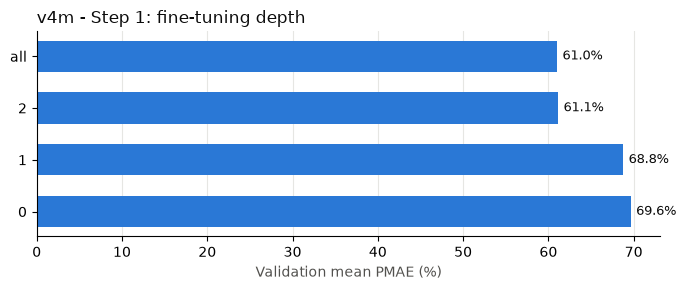

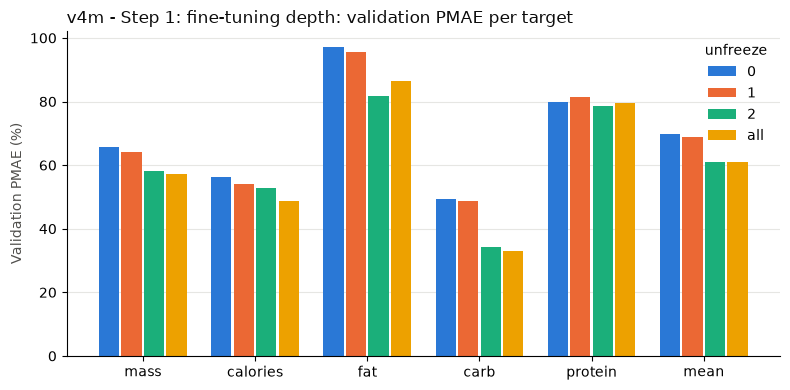

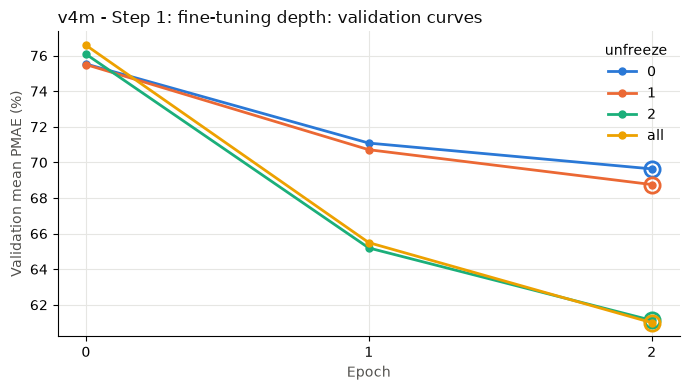

v4m - Step 2: head grouping


,run,status,epochs_done,best_epoch,val_mean_pmae,test_mean_pmae,test_clean_mean_pmae,params_M,trainable_M,sec_per_epoch,heads
14,v4m-ft_2-grouped-h512-224-complete-pilot-fbn-c...,done,3,2,57.640275,57.980899,57.980899,9.485653,7.860773,8.499628,grouped
21,v4m-ft_2-single-h512-224-complete-pilot-fbn-cl...,done,3,2,61.124940,58.190343,58.190343,9.222997,7.598117,8.371530,single
15,v4m-ft_2-per-target-h512-224-complete-pilot-fb...,done,3,2,63.224774,65.587560,65.587560,9.748309,8.123429,8.528701,per-target


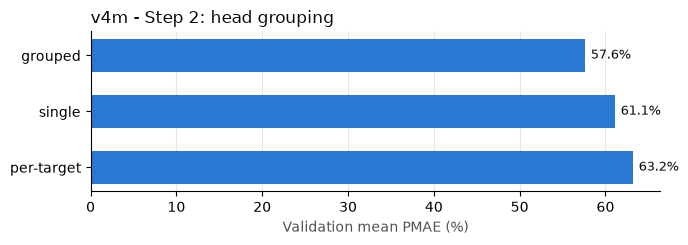

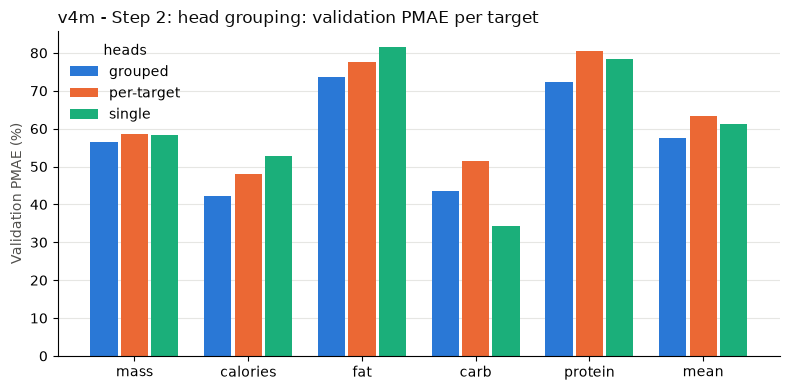

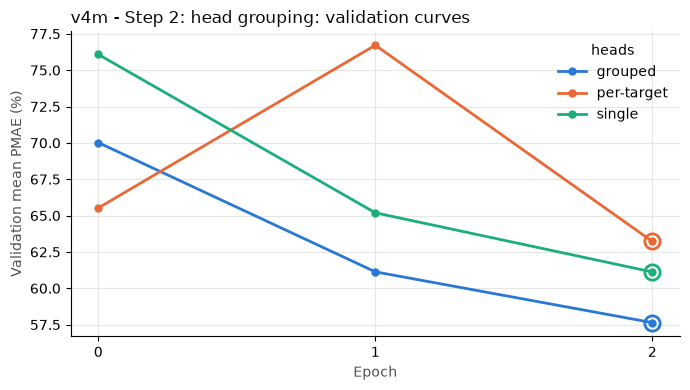

v4m - Step 3: trunk size


,run,status,epochs_done,best_epoch,val_mean_pmae,test_mean_pmae,test_clean_mean_pmae,params_M,trainable_M,sec_per_epoch,hidden
16,v4m-ft_2-single-h0-224-complete-pilot-fbn-clea...,done,3,2,55.198605,56.472905,56.472905,8.763733,7.138853,8.396772,0
21,v4m-ft_2-single-h512-224-complete-pilot-fbn-cl...,done,3,2,61.124940,58.190343,58.190343,9.222997,7.598117,8.371530,512
20,v4m-ft_2-single-h1024x1024-224-complete-pilot-...,done,3,2,64.576187,60.366893,60.366893,11.059541,9.434661,8.624156,1024x1024


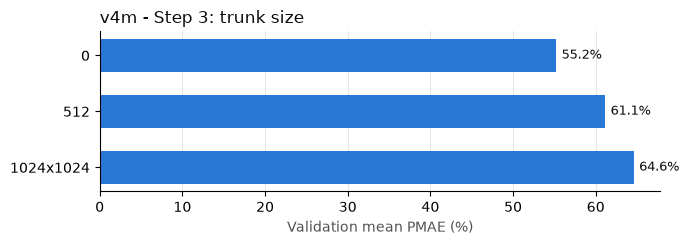

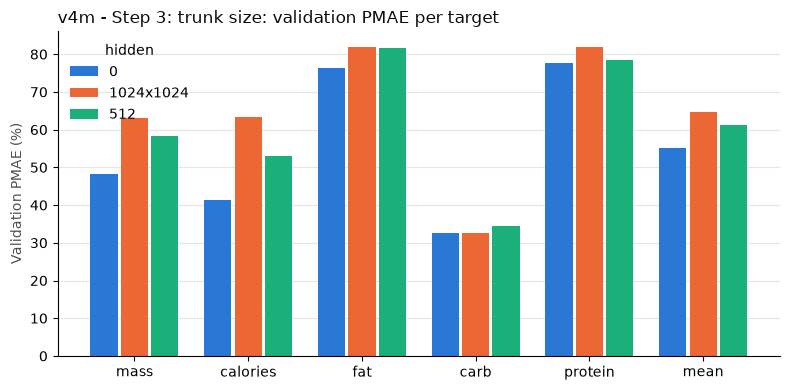

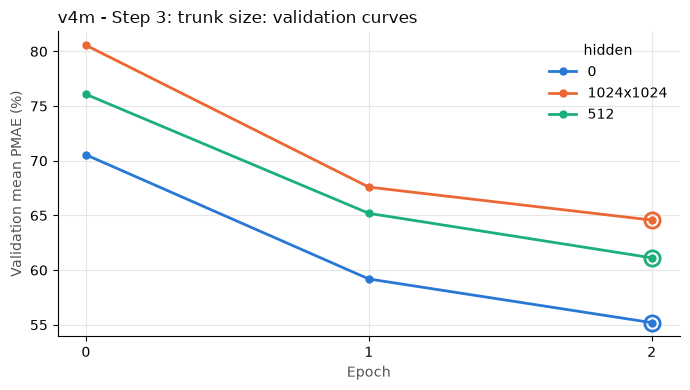

v4m - Step 4: image size


,run,status,epochs_done,best_epoch,val_mean_pmae,test_mean_pmae,test_clean_mean_pmae,params_M,trainable_M,sec_per_epoch,image_size
16,v4m-ft_2-single-h0-224-complete-pilot-fbn-clea...,done,3,2,55.198605,56.472905,56.472905,8.763733,7.138853,8.396772,224
19,v4m-ft_2-single-h0-256-complete-pilot-fbn-clea...,done,3,2,57.676686,58.462154,58.462154,8.763733,7.138853,10.100583,256


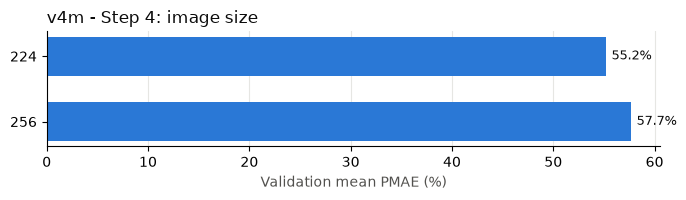

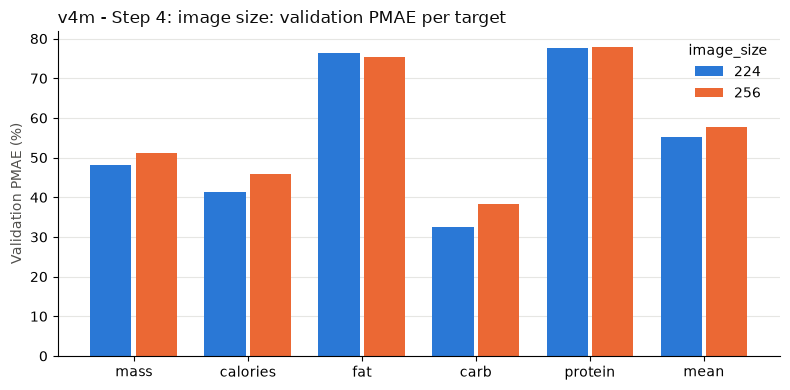

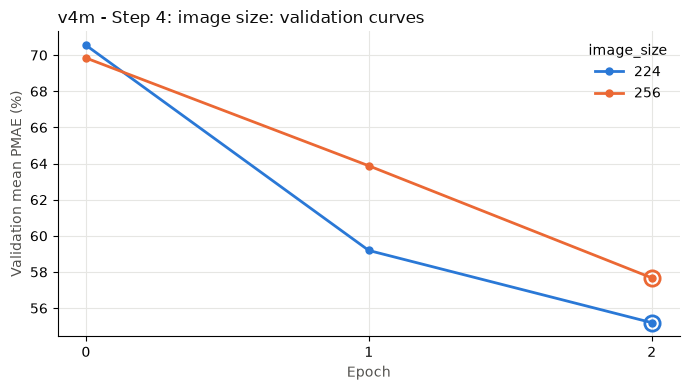

In [5]:
BACKBONES = ("v3", "v4m")
BEST_UNFREEZE = {"v3": "2", "v4m": "2"}
BEST_HEADS = {"v3": "single", "v4m": "single"}
BEST_HIDDEN = {"v3": "512", "v4m": "0"}

for backbone in BACKBONES:
    unfreeze, heads, hidden = BEST_UNFREEZE[backbone], BEST_HEADS[backbone], BEST_HIDDEN[backbone]
    steps(runs, backbone, {
        "Step 1: fine-tuning depth": ("unfreeze", dict(heads="single", hidden="512", image_size=224, seed=0)),
        "Step 2: head grouping": ("heads", dict(unfreeze=unfreeze, hidden="512", image_size=224, seed=0)),
        "Step 3: trunk size": ("hidden", dict(unfreeze=unfreeze, heads=heads, image_size=224, seed=0)),
        "Step 4: image size": ("image_size", dict(unfreeze=unfreeze, heads=heads, hidden=hidden, seed=0)),
    })

## Error por objetivo (test) de todas las ejecuciones terminadas

Ordenadas por validación. Solo se informa: no sirve para elegir.

In [6]:
target_table(runs[runs["status"] == "done"], "run", split="test")

## Evolución por objetivo de una ejecución

Comprueba si un objetivo empeora mientras la media mejora. La línea negra es la media; la vertical marca la época elegida.

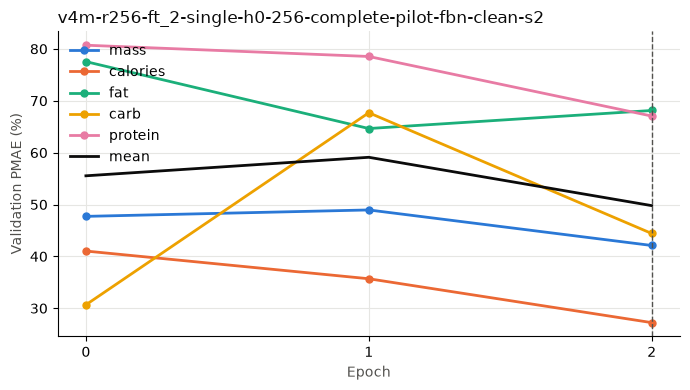

In [7]:
BEST = runs[runs["status"] == "done"].iloc[0]  # el mejor por validación; o all_runs[all_runs["run"] == "<nombre>"].iloc[0]
target_curves(BEST["path"])

## Etapa 3 (L3): media ± SD entre semillas

Una fila por configuración con más de una semilla; gráficas con el error de cada semilla (puntos) y la media ± SD.

seeds   val_mean    val_sd  test_mean   test_sd  test_clean_mean  test_clean_sd
family    backbone unfreeze heads  hidden image_size backbone_lr                                                                                 
mobilenet v4m-r256 2        single 0      256        0.0001           3  53.013601  4.121180  60.238739  3.436907        60.238739       3.436907
          v4m      2        single 0      224        0.0001           3  59.800603  6.523586  58.273869  7.071264        58.273869       7.071264
          v3       2        single 512    224        0.0001           3  65.220580  2.280083  57.890260  1.741088        57.890260       1.741088

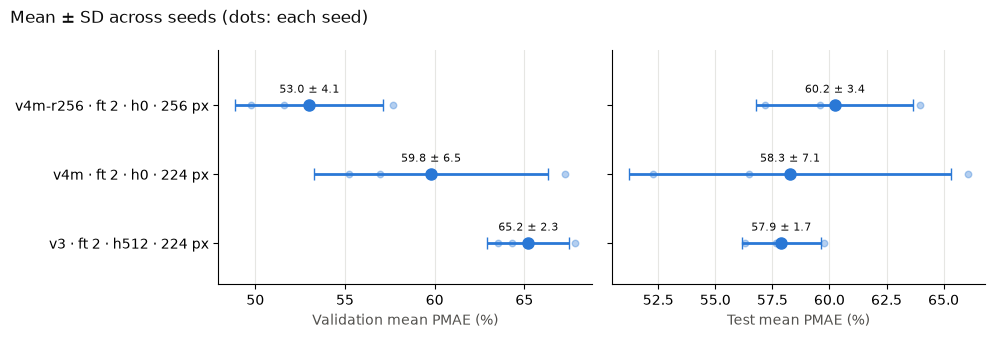

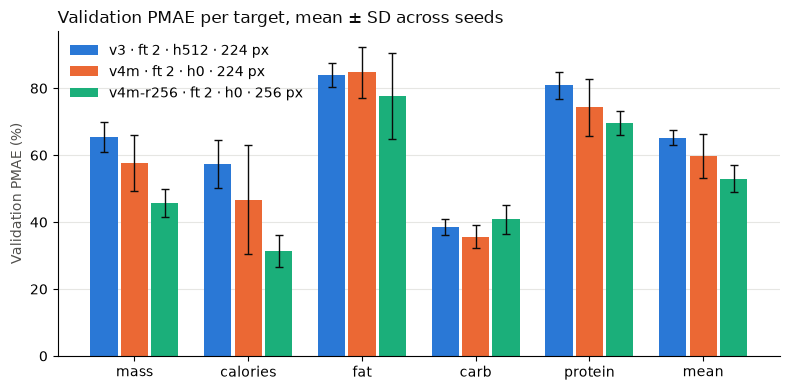

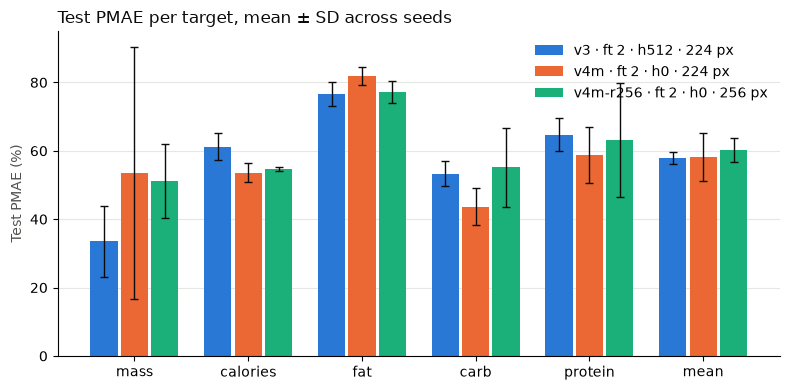

In [8]:
seed_runs = seed_groups(runs)
if len(seed_runs):
    display(seed_table(seed_runs))
    seed_spread(seed_runs)
    seed_targets(seed_runs, "val")
    seed_targets(seed_runs, "test")
else:
    print("no configuration with more than one seed yet")

## Métricas de test de los modelos finales

MAE, PMAE, RMSE y R² por objetivo, con la línea base como referencia. Por defecto, los tres mejores runs por
validación. Debajo, la media ± SD que escribe `train --all-seeds`.

In [9]:
FINAL = runs[runs["status"] == "done"].head(3)  # o select(runs, backbone=..., unfreeze=...)
test_metrics(FINAL, SPLIT).round(2)

unit     MAE  PMAE (%)    RMSE    R²
model                                              target                                        
v4m-r256-ft_2-single-h0-256-complete-pilot-fbn-... mass         g   46.71     40.57   60.05 -0.90
                                                   calories  kcal  147.67     54.05  162.94 -0.10
                                                   fat          g   14.17     75.06   17.51 -0.30
                                                   carb         g    9.19     67.82   10.66 -1.41
                                                   protein      g   11.82     82.28   14.60 -1.44
                                                   mean       NaN     NaN     63.96     NaN   NaN
v4m-r256-ft_2-single-h0-256-complete-pilot-fbn-... mass         g   58.20     50.55   62.76 -1.08
                                                   calories  kcal  150.18     54.97  191.27 -0.52
                                                   fat          g   15.26     80.85   20.25 -0.73
                                                   carb         g    6.19     45.71    7.21 -0.11
                                                   protein      g    7.73     53.80    8.99  0.07
                                                   mean       NaN     NaN     57.18     NaN   NaN
v4m-ft_2-single-h0-224-complete-pilot-fbn-clean-s0 mass         g   41.80     36.31   50.88 -0.36
                                                   calories  kcal  153.63     56.23  191.95 -0.53
                                                   fat          g   15.96     84.53   20.74 -0.82
                                                   carb         g    5.14     37.91    7.82 -0.30
                                                   protein      g    9.68     67.38   12.12 -0.68
                                                   mean       NaN     NaN     56.47     NaN   NaN
average baseline                                   mass         g   67.98     59.05   79.36 -2.32
                                                   calories  kcal  143.70     52.60  159.45 -0.05
                                                   fat          g   14.16     74.99   16.25 -0.12
                                                   carb         g    5.13     37.83    7.06 -0.06
                                                   protein      g    7.34     51.10    9.73 -0.09
                                                   mean       NaN     NaN     55.11     NaN   NaN

In [10]:
seed_files(FAMILY, SPLIT, MODE)

,configuration,val_mean_pmae,test_mean_pmae,test_clean_mean_pmae,test_mass_pmae,test_calories_pmae,test_fat_pmae,test_carb_pmae,test_protein_pmae
0,v3-ft_2-single-h512-224-complete-pilot-fbn-clean,65.22 ± 2.28,57.89 ± 1.74,57.89 ± 1.74,33.53 ± 10.47,61.19 ± 3.91,76.70 ± 3.48,53.35 ± 3.54,64.68 ± 4.84
1,v4m-ft_2-single-h0-224-complete-pilot-fbn-clean,59.80 ± 6.52,58.27 ± 7.07,58.27 ± 7.07,53.59 ± 36.84,53.60 ± 2.85,81.83 ± 2.70,43.64 ± 5.35,58.71 ± 8.16
2,v4m-r256-ft_2-single-h0-256-complete-pilot-fbn...,53.01 ± 4.12,60.24 ± 3.44,60.24 ± 3.44,51.12 ± 10.84,54.65 ± 0.52,77.17 ± 3.20,55.12 ± 11.42,63.15 ± 16.57


## Galería de platos de test

Los platos con menor error, los de mayor error y algunos al azar de un run, con su primer frame, el valor real y
el predicho. Necesita los frames en `data/`.

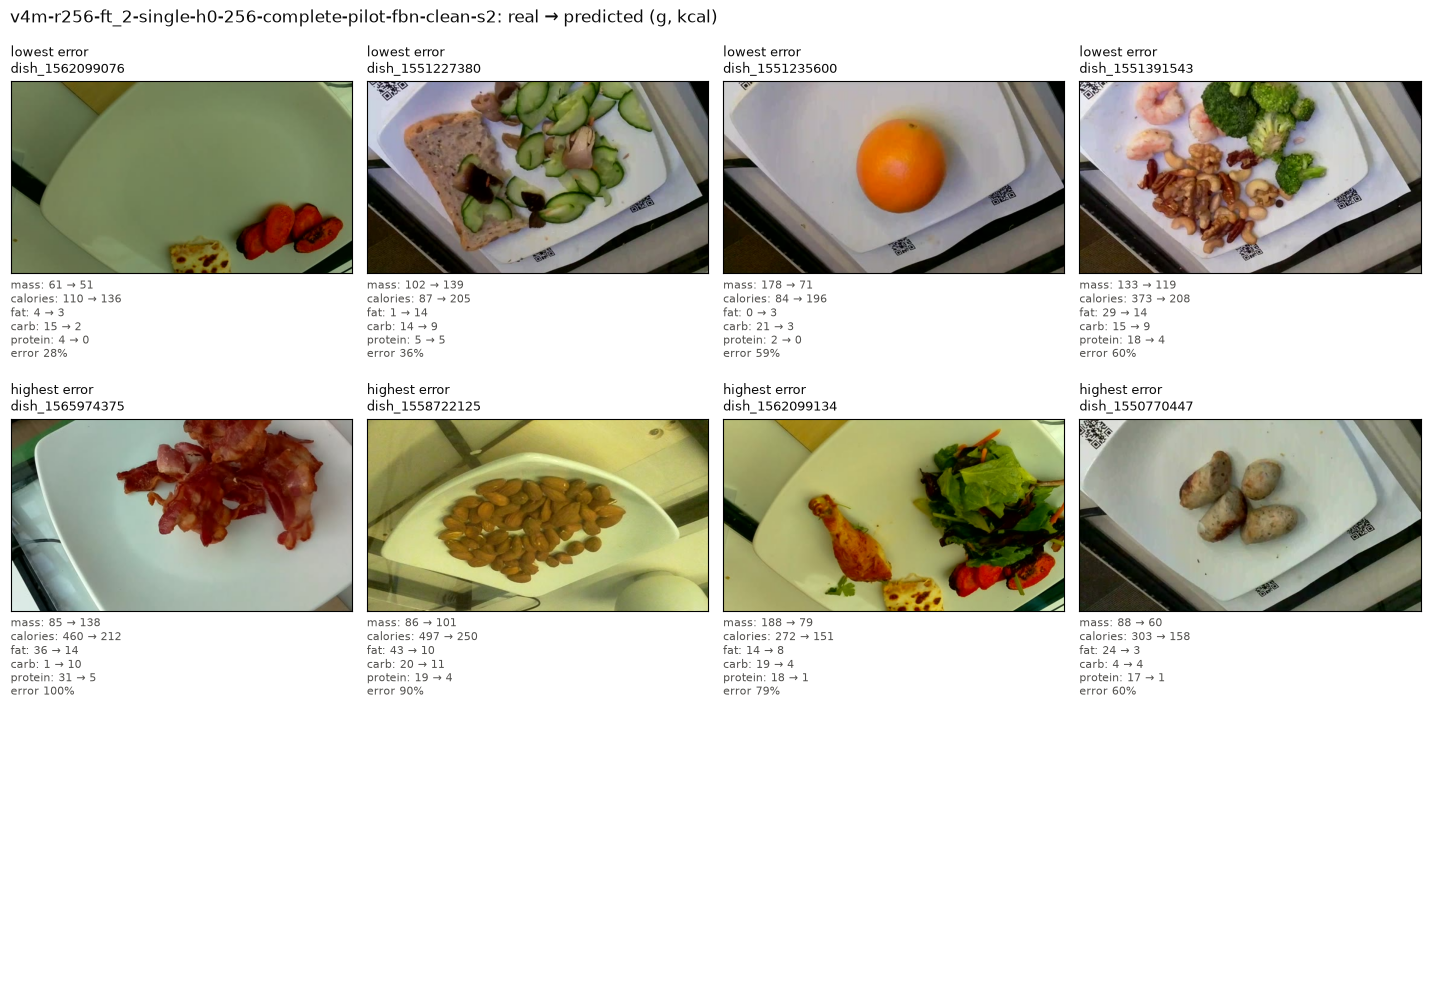

In [11]:
gallery(BEST["path"], SPLIT, MODE)